# 3.  Codificación de variables

Conjunto de datos: titanic (incluido en seaborn)

Este conjunto de datos es excelente para trabajar con variables categóricas.

In [10]:
# Importar librerías necesarias
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
import matplotlib.pyplot as plt

In [2]:
# Cargar el conjunto de datos
data = sns.load_dataset('titanic')

In [3]:
# Visualizar las primeras filas
print("Conjunto de datos Titanic:")
data.head()

Conjunto de datos Titanic:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
# Seleccionar columnas categóricas
categorical_cols = ['sex', 'embarked', 'class']

In [5]:
# Codificar con LabelEncoder
label_encoder = LabelEncoder()
data['sex_label'] = label_encoder.fit_transform(data['sex'])

In [6]:
# Codificar con OneHotEncoder
onehot_encoder = pd.get_dummies(data['embarked'], prefix='embarked')

In [7]:
# Combinar con el conjunto original
data = pd.concat([data, onehot_encoder], axis=1)

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado. Crea gráficas en donde veas correcto.

### 1. ¿Qué diferencias encuentras entre LabelEncoder y OneHotEncoder?

In [8]:
# Ver codificación con LabelEncoder
print("LabelEncoder para 'sex':")
print(data[['sex', 'sex_label']].head())

# Ver codificación tipo OneHot para 'embarked'
print("\nOneHotEncoder para 'embarked':")
print(data[['embarked', 'embarked_C', 'embarked_Q', 'embarked_S']].head())

# Mostrar las categorías asignadas por LabelEncoder
print("Clases de sex:")
print(label_encoder.classes_)

# Mostrar columnas generadas con One Hot Encoding
print("\nColumnas generadas:")
print(onehot_encoder.columns)

# LabelEncoder asigna un valor numérico a cada categoría dentro de una sola columna, 
# mientras que OneHotEncoder crea una columna binaria para cada categoría. 
# OneHotEncoder evita que el modelo interprete las categorías como si tuvieran un orden numérico.

LabelEncoder para 'sex':
      sex  sex_label
0    male          1
1  female          0
2  female          0
3  female          0
4    male          1

OneHotEncoder para 'embarked':
  embarked  embarked_C  embarked_Q  embarked_S
0        S       False       False        True
1        C        True       False       False
2        S       False       False        True
3        S       False       False        True
4        S       False       False        True
Clases de sex:
['female' 'male']

Columnas generadas:
Index(['embarked_C', 'embarked_Q', 'embarked_S'], dtype='str')


### 2. Crea una gráfica de barras comparando las frecuencias de 'sex' antes y después de la codificación con LabelEncoder.

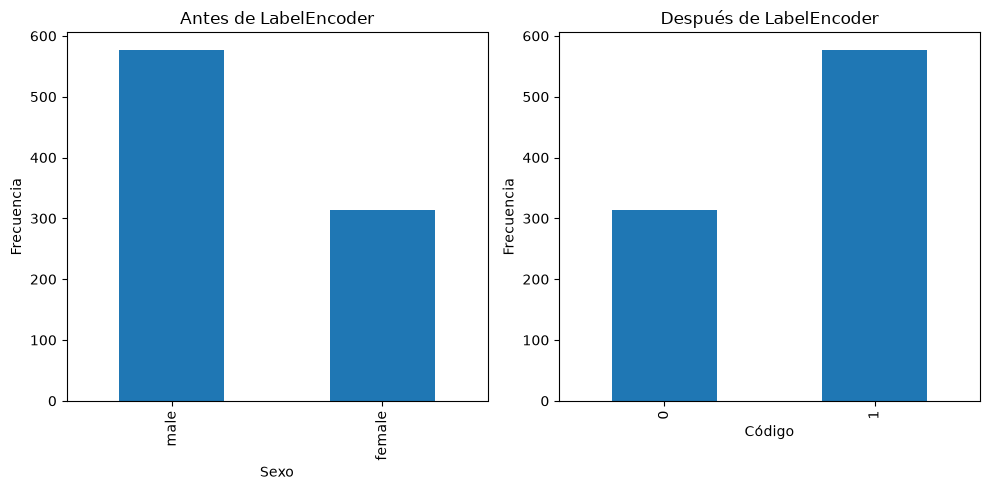

In [11]:
# Frecuencias antes de la codificación
sex_original = data["sex"].value_counts()

# Frecuencias después de LabelEncoder
sex_codificado = data["sex_label"].value_counts().sort_index()

# Crear gráfica
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

sex_original.plot(kind="bar", ax=ax[0])
ax[0].set_title("Antes de LabelEncoder")
ax[0].set_xlabel("Sexo")
ax[0].set_ylabel("Frecuencia")

sex_codificado.plot(kind="bar", ax=ax[1])
ax[1].set_title("Después de LabelEncoder")
ax[1].set_xlabel("Código")
ax[1].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

### 3. Utiliza OneHotEncoder para codificar la columna 'class'. ¿Qué ventajas tiene este enfoque frente a LabelEncoder?

In [12]:
# Codificar la columna 'class' con OneHotEncoder usando get_dummies
class_encoded = pd.get_dummies(data["class"], prefix="class")

# Agregar las nuevas columnas al DataFrame
data = pd.concat([data, class_encoded], axis=1)

# Ver resultado
data[["class", "class_First", "class_Second", "class_Third"]].head()

#OneHotEncoder evita introducir un orden numérico artificial entre categorías. 
# Esto permite representar cada clase de manera independiente mediante 
# variables binarias.

,class,class_First,class_Second,class_Third
0,Third,False,False,True
1,First,True,False,False
2,Third,False,False,True
3,First,True,False,False
4,Third,False,False,True


### 4. Si quisieras aplicar un modelo de aprendizaje automático, ¿qué tipo de codificación elegirías para las variables categóricas? Explica tu respuesta.

In [13]:
# Seleccionar variables categóricas
categorical_cols = ["sex", "embarked", "class"]

# Aplicar One-Hot Encoding
data_encoded = pd.get_dummies(
    data,
    columns=categorical_cols,
    drop_first=False
)

# Ver resultado
data_encoded.head()

#Elegiría One-Hot Encoding para variables categóricas nominales, 
#porque representa cada categoría de forma independiente y evita introducir 
#relaciones numéricas artificiales. Si la variable tiene un orden natural, 
#usaría una codificación ordinal.

,survived,pclass,age,sibsp,parch,fare,who,adult_male,deck,embark_town,...,class_Second,class_Third,sex_female,sex_male,embarked_C,embarked_Q,embarked_S,class_First,class_Second,class_Third
0,0,3,22.0,1,0,7.2500,man,True,NaN,Southampton,...,False,True,False,True,False,False,True,False,False,True
1,1,1,38.0,1,0,71.2833,woman,False,C,Cherbourg,...,False,False,True,False,True,False,False,True,False,False
2,1,3,26.0,0,0,7.9250,woman,False,NaN,Southampton,...,False,True,True,False,False,False,True,False,False,True
3,1,1,35.0,1,0,53.1000,woman,False,C,Southampton,...,False,False,True,False,False,False,True,True,False,False
4,0,3,35.0,0,0,8.0500,man,True,NaN,Southampton,...,False,True,False,True,False,False,True,False,False,True
